# Customer Churn Prediction Using Machine Learning

**Dataset:** IBM Telco Customer Churn Dataset

**Algorithms:** Logistic Regression, Decision Tree, Random Forest, KNN, SVM

## 1. Objective

To predict customer churn using Machine Learning classification algorithms
and compare their performance using accuracy, precision, recall, and F1-score.

## 2. Problem Statement

Customer churn occurs when a customer stops using a company's services.
This project uses historical customer data to predict whether a customer
will leave the company.

## 3. Dataset Description

The IBM Telco Customer Churn dataset contains customer demographics,
services, contract details, billing information, and churn status.

- Original records: 7,043
- Original columns: 21
- Target column: Churn
- Churn categories: Yes and No
- Problem type: Binary classification

## 4. Import Required Libraries

The following Python libraries are used to load and analyze the dataset, preprocess customer data, train Machine Learning models, evaluate their performance, and create visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


## 5. Load the Dataset

In this step, we load the Telco Customer Churn dataset from the `dataset` folder using the Pandas library. The dataset contains customer information that will be used for analysis and prediction.

In [2]:
# Load the customer churn dataset
df = pd.read_csv("dataset/Telco-Customer-Churn.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first 5 records
display(df.head())

Dataset loaded successfully!
Number of records: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset. In this step, we check the number of records and columns, column names, data types, and missing values.

In [3]:

#  Explore the dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


## 7. Churn Distribution

In this step, we count how many customers stayed with the company and how many customers left. This helps us understand the distribution of the target variable, `Churn`.

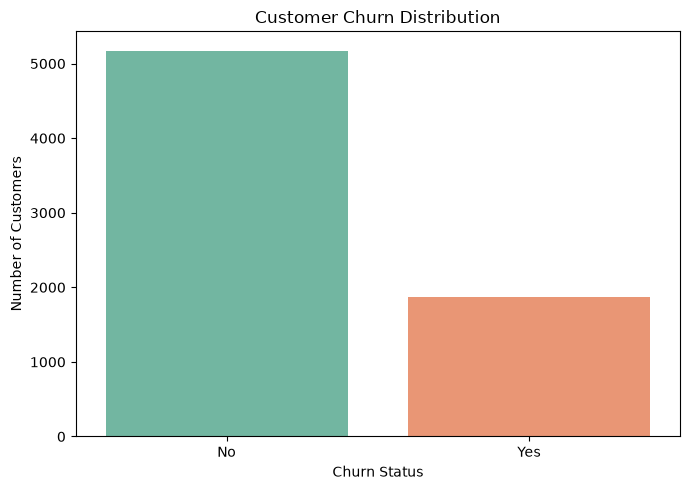

In [4]:

#  Visualize customer churn distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [5]:

churn_counts = df["Churn"].value_counts()

print("Customers who stayed:", churn_counts.get("No", 0))
print("Customers who left:", churn_counts.get("Yes", 0))

print("\nObservation:")
print("The dataset contains more non-churning customers than churning customers.")


Customers who stayed: 5174
Customers who left: 1869

Observation:
The dataset contains more non-churning customers than churning customers.


In [6]:

#  Data cleaning

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Missing values before cleaning:")
print(df.isnull().sum().sum())

# Remove rows containing missing values
df = df.dropna().copy()

# Remove duplicate records, if any
df = df.drop_duplicates().copy()

print("\nDataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate records after cleaning:")
print(df.duplicated().sum())


Missing values before cleaning:
11

Dataset shape after cleaning: (7032, 21)

Missing values after cleaning:
0

Duplicate records after cleaning:
0


## 8. Data Preprocessing

Data preprocessing prepares the dataset for Machine Learning. In this step, we remove duplicate records, convert `TotalCharges` into numeric values, handle missing values, and remove the `customerID` column because it is only an identifier.

In [7]:
# Make a copy of the dataset
df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Convert TotalCharges to numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove rows with missing target values
df = df.dropna(subset=["Churn"])

# Display missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum())

# Remove customerID because it is an identifier
df = df.drop(columns=["customerID"], errors="ignore")

print("\nDataset shape after preprocessing:", df.shape)
print("\nPreprocessing completed successfully!")

Missing values after conversion:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Dataset shape after preprocessing: (7032, 20)

Preprocessing completed successfully!


## 9. Separate Input Features and Target Variable

In this step, we separate the dataset into input features (`X`) and the target variable (`y`).

- **X:** Contains customer information used to make predictions.
- **y:** Contains the `Churn` column, which indicates whether a customer left the company (`Yes`) or stayed (`No`).

In [8]:
# Separate input features and target variable
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Display the shapes and target categories
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Categories:")
print(y.value_counts())

Input Features Shape: (7032, 19)
Target Variable Shape: (7032,)

Target Categories:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


## 10. Split Training and Testing Data

In this step, we divide the dataset into training data and testing data.

- **80% Training Data:** Used to train the Machine Learning models.
- **20% Testing Data:** Used to evaluate the trained models.

In [10]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining data percentage: 80%")
print("Testing data percentage: 20%")

Training Features: (5625, 19)
Testing Features: (1407, 19)

Training Target: (5625,)
Testing Target: (1407,)

Training data percentage: 80%
Testing data percentage: 20%


## 11. Prepare the Data for Machine Learning Models

In this step, we prepare numerical and categorical features separately.

- **Numerical features:** Missing values are filled using the median, and values are standardized using StandardScaler.
- **Categorical features:** Missing values are filled using the most frequent value, and categories are converted into numerical form using OneHotEncoder.
- **ColumnTransformer:** Applies the correct preprocessing to each type of feature.

In [11]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully!


C:\Users\patil\AppData\Local\Temp\ipykernel_19368\4142852372.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


## 12. Train Five Machine Learning Models

In this step, we train five classification algorithms to predict customer churn.

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)

Each model uses the same preprocessing pipeline and training dataset so that their performance can be compared fairly.

In [14]:
# Define five Machine Learning models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(random_state=42)
}

# Train each model using the preprocessing pipeline
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll five models have been trained.")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
SVM trained successfully!

All five models have been trained.


## 13. Evaluate Model Performance

In this step, we evaluate all five trained Machine Learning models using the testing dataset.

The evaluation metrics are:

- **Accuracy:** Percentage of correct predictions.
- **Precision:** How many predicted churn cases were actually churn cases.
- **Recall:** How many actual churn cases were correctly identified.
- **F1-score:** Balance between precision and recall.

We use these metrics to compare the performance of the models.

In [15]:
# Evaluate all trained models
results = []

for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, y_pred, pos_label="Yes", zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, y_pred, pos_label="Yes", zero_division=0) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(y_test, y_pred, pos_label="Yes", zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df)

Model Evaluation Results:


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.38,64.85,57.22,60.80
1,Decision Tree,73.06,49.34,49.73,49.53
2,Random Forest,78.75,63.07,48.40,54.77
3,KNN,76.05,54.68,57.75,56.18
4,SVM,79.18,64.01,49.47,55.81


## 14. Compare All Five Models

In this step, we compare the performance of Logistic Regression, Decision Tree, Random Forest, KNN, and SVM using their evaluation metrics.

The comparison helps us identify which model performs best for customer churn prediction.

In [16]:
# Sort models by accuracy from highest to lowest
comparison_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("Comparison of All Five Models:")
display(comparison_df)

# Display the best model based on accuracy
best_model_name = comparison_df.loc[0, "Model"]

print("\nBest Model Based on Accuracy:", best_model_name)
print(
    "Best Accuracy:",
    comparison_df.loc[0, "Accuracy (%)"],
    "%"
)

Comparison of All Five Models:


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.38,64.85,57.22,60.80
1,SVM,79.18,64.01,49.47,55.81
2,Random Forest,78.75,63.07,48.40,54.77
3,KNN,76.05,54.68,57.75,56.18
4,Decision Tree,73.06,49.34,49.73,49.53



Best Model Based on Accuracy: Logistic Regression
Best Accuracy: 80.38 %


## 15. Visualize Model Performance

Data visualization helps us compare the performance of all five Machine Learning models. In this step, we create a bar chart to compare their accuracy percentages. The chart makes it easier to identify the model with the highest accuracy.

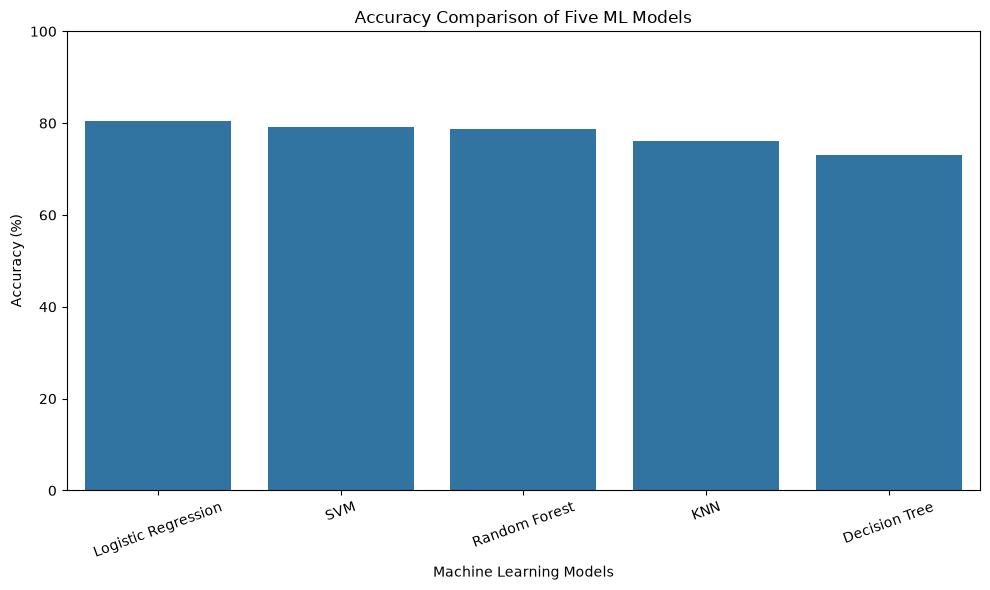

In [17]:
# Plot accuracy comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 16. Select and Save the Best Model

In this step, we select the best-performing model based on accuracy and save the complete Machine Learning pipeline using Joblib.

The saved pipeline includes both data preprocessing and the trained model. It can be reused later in the Flask web application to predict customer churn without training the model again.

In [19]:
import os
import joblib

# Select the best model based on accuracy
best_model_name = comparison_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

# Create the model directory if it does not exist
os.makedirs("model", exist_ok=True)

# Save the complete pipeline
model_path = "model/churn_model.pkl"
joblib.dump(best_model, model_path)

print("Best Model:", best_model_name)
print("Accuracy:", comparison_df.loc[0, "Accuracy (%)"], "%")
print("Model saved successfully at:", model_path)

Best Model: Logistic Regression
Accuracy: 80.38 %
Model saved successfully at: model/churn_model.pkl


## 17. Predict Customer Churn

In this step, we use the saved best Machine Learning model to predict whether a customer will leave the company or continue using its services. We select one customer record from the testing dataset and display the actual result and predicted result.

In [20]:
# Load the saved model
loaded_model = joblib.load("model/churn_model.pkl")

# Select one customer from the testing dataset
sample_customer = X_test.iloc[[0]]
actual_result = y_test.iloc[0]

# Predict customer churn
predicted_result = loaded_model.predict(sample_customer)[0]

print("Actual Churn:", actual_result)
print("Predicted Churn:", predicted_result)

if predicted_result == "Yes":
    print("Result: This customer is predicted to leave the company.")
else:
    print("Result: This customer is predicted to stay with the company.")

Actual Churn: No
Predicted Churn: No
Result: This customer is predicted to stay with the company.


In [22]:
import joblib

loaded_model = joblib.load("model/churn_model.pkl")

print(
    "Selected model:",
    type(loaded_model.named_steps["classifier"]).__name__
)

print(
    "Supports probability:",
    hasattr(loaded_model, "predict_proba")
)

Selected model: LogisticRegression
Supports probability: True


## 18. Build the Flask Web Application

Flask is a Python web framework used to create web applications. In this project, Flask connects the saved Machine Learning model to a web interface. Users will enter customer details, and the application will predict whether the customer is likely to leave the company or stay.